# Linear and Quadratic Discriminant Analysis

Generative classifiers: model each class as a **multivariate Gaussian** (its own mean), then classify by Bayes' rule — pick the class with the highest posterior. Unlike Gaussian Naive Bayes (`12_naive_bayes`), features are **not** assumed independent: the full covariance matrix is used, so correlated features are handled properly.

| | Covariance | Decision boundary | Use when |
|---|---|---|---|
| **LDA** | one matrix shared by all classes (pooled) | straight lines | few samples, classes have similar spread |
| **QDA** | one matrix per class | curves (quadratic) | plenty of samples, classes differ in spread |

LDA has fewer parameters to estimate (more stable); QDA is more flexible but needs enough samples per class — `reg` adds `reg·I` to each covariance when a class is small or features are collinear.

Scores are log-posteriors up to a constant; the class priors come from the training class frequencies. (LDA is also a classic supervised dimensionality-reduction tool — that projection isn't implemented here, only the classifier.)

## Usage

```python
# (the class is defined in the Implementation section below)

lda = LinearDiscriminantAnalysis().fit(X_train, y_train)
qda = QuadraticDiscriminantAnalysis(reg=1e-6).fit(X_train, y_train)
preds = lda.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class _GaussianDiscriminant:
    def _setup(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        self.priors = np.bincount(y_enc) / len(y_enc)
        self.means = np.array([X[y_enc == c].mean(axis=0) for c in range(len(self.classes_))])
        return X, y_enc

    def predict(self, X):
        return self.classes_[np.argmax(self._scores(np.asarray(X, dtype=float)), axis=1)]


class LinearDiscriminantAnalysis(_GaussianDiscriminant):
    """Each class is a Gaussian; all classes share ONE covariance matrix. The log-posterior is then
    linear in x, so decision boundaries are straight lines (hyperplanes):

        score_k(x) = x . S^-1 mu_k  -  0.5 * mu_k . S^-1 mu_k  +  log prior_k"""

    def fit(self, X, y):
        X, y_enc = self._setup(X, y)
        centered = X - self.means[y_enc]
        pooled_cov = centered.T @ centered / (len(X) - len(self.classes_))  # within-class covariance
        self.coef = np.linalg.solve(pooled_cov, self.means.T).T  # S^-1 mu_k, one row per class
        self.intercept = -0.5 * np.sum(self.coef * self.means, axis=1) + np.log(self.priors)
        return self

    def _scores(self, X):
        return X @ self.coef.T + self.intercept


class QuadraticDiscriminantAnalysis(_GaussianDiscriminant):
    """Each class gets its OWN covariance matrix, so boundaries are curved (quadratic):

        score_k(x) = -0.5 * log|S_k| - 0.5 * (x - mu_k)' S_k^-1 (x - mu_k) + log prior_k

    reg adds reg * I to every covariance (needed when a class has fewer samples than features)."""

    def __init__(self, reg=0.0):
        self.reg = reg

    def fit(self, X, y):
        X, y_enc = self._setup(X, y)
        d = X.shape[1]
        self.covs = [np.cov(X[y_enc == c], rowvar=False) + self.reg * np.eye(d) for c in range(len(self.classes_))]
        return self

    def _scores(self, X):
        scores = []
        for mu, cov, prior in zip(self.means, self.covs, self.priors):
            diff = X - mu
            maha = np.sum(diff * np.linalg.solve(cov, diff.T).T, axis=1)  # squared Mahalanobis distance
            scores.append(-0.5 * np.linalg.slogdet(cov)[1] - 0.5 * maha + np.log(prior))
        return np.array(scores).T

## See it work

### 1. Shared vs separate covariance

Both models fit one Gaussian per class and classify by which Gaussian is most likely. **LDA** forces all classes to share one covariance matrix, which makes the boundary a straight line. **QDA** gives each class its own covariance, so the boundary can be a curve. When the true class shapes differ, QDA wins; when they are the same, LDA is as good and needs fewer parameters.

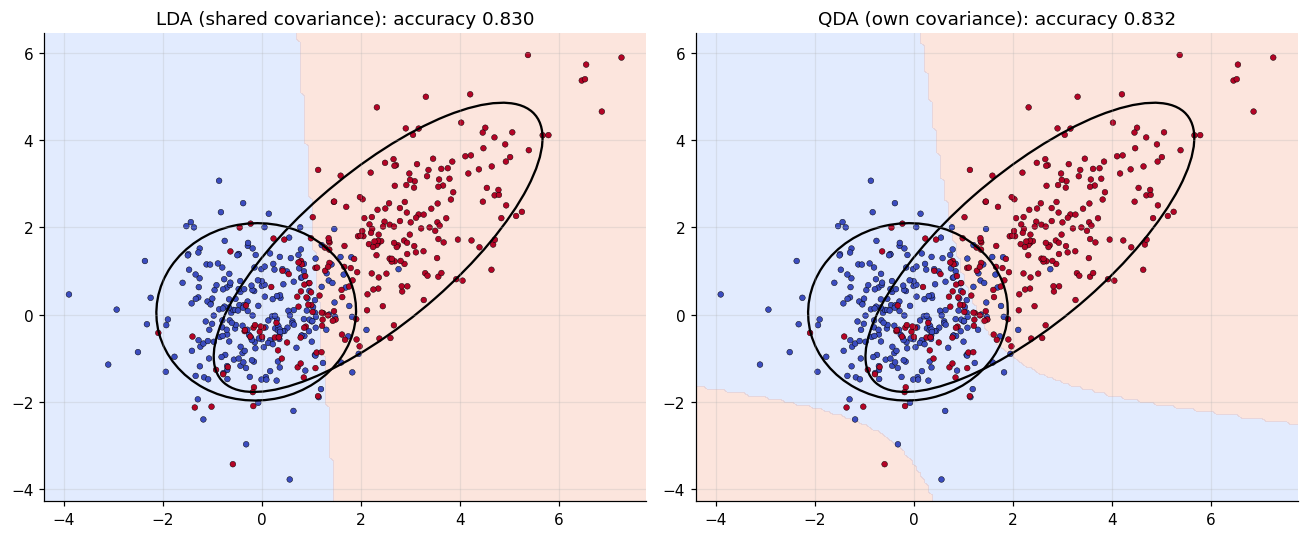

In [3]:
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)
from matplotlib.patches import Ellipse

rng = np.random.default_rng(0)
A = rng.multivariate_normal([0, 0], [[1.0, 0.0], [0.0, 1.0]], 250)
B = rng.multivariate_normal([2.2, 1.5], [[3.0, 2.2], [2.2, 3.0]], 250)
X = np.vstack([A, B]); y = np.array([0] * 250 + [1] * 250)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model, name in [(axes[0], LinearDiscriminantAnalysis(), "LDA (shared covariance)"), (axes[1], QuadraticDiscriminantAnalysis(), "QDA (own covariance)")]:
    model.fit(X, y); plot_boundary(ax, model, X, y)
    for c, col in zip((A, B), ("C0", "C3")):
        vals, vecs = np.linalg.eigh(np.cov(c.T)); ang = np.degrees(np.arctan2(*vecs[:, 1][::-1]))
        ax.add_patch(Ellipse(c.mean(0), 4 * np.sqrt(vals[1]), 4 * np.sqrt(vals[0]), angle=ang, fill=False, color="k", lw=1.5))
    ax.set_title(f"{name}: accuracy {(model.predict(X) == y).mean():.3f}")
plt.tight_layout(); plt.show()

### 2. With equal covariances, LDA is the right amount of flexibility

Same class shapes, shifted. The best boundary is a straight line, LDA finds it with few parameters, and QDA gains nothing for its extra parameters: the two test accuracies below are essentially equal.

In [4]:
cov = [[2.0, 1.2], [1.2, 1.0]]
Xe = np.vstack([rng.multivariate_normal([0, 0], cov, 40), rng.multivariate_normal([2, 1.5], cov, 40)]); ye = np.array([0] * 40 + [1] * 40)
Xt = np.vstack([rng.multivariate_normal([0, 0], cov, 2000), rng.multivariate_normal([2, 1.5], cov, 2000)]); yt = np.array([0] * 2000 + [1] * 2000)
for name, model in [("LDA", LinearDiscriminantAnalysis()), ("QDA", QuadraticDiscriminantAnalysis())]:
    print(f"{name}: test accuracy with 80 training points = {(model.fit(Xe, ye).predict(Xt) == yt).mean():.3f}")

LDA: test accuracy with 80 training points = 0.750
QDA: test accuracy with 80 training points = 0.749


## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [5]:
from sklearn.datasets import load_wine
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as SklearnLDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as SklearnQDA
from sklearn.model_selection import train_test_split

data = load_wine()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

for name, ours, theirs in (
    ("LDA", LinearDiscriminantAnalysis(), SklearnLDA()),
    ("QDA", QuadraticDiscriminantAnalysis(), SklearnQDA()),
):
    ours.fit(X_train, y_train)
    theirs.fit(X_train, y_train)
    acc_ours = (ours.predict(X_test) == y_test).mean()
    acc_theirs = (theirs.predict(X_test) == y_test).mean()
    print("wine %s test accuracy: ours=%.4f sklearn=%.4f" % (name, acc_ours, acc_theirs))
    assert (ours.predict(X_test) == theirs.predict(X_test)).all()

wine LDA test accuracy: ours=1.0000 sklearn=1.0000
wine QDA test accuracy: ours=0.9815 sklearn=0.9815


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [6]:
import numpy as np


def test_lda_separates_gaussians_with_shared_covariance():
    rng = np.random.default_rng(0)
    cov = [[1.0, 0.8], [0.8, 1.0]]
    X = np.vstack([rng.multivariate_normal([0, 0], cov, 150), rng.multivariate_normal([3, 0], cov, 150)])
    y = np.array(["a"] * 150 + ["b"] * 150)
    assert (LinearDiscriminantAnalysis().fit(X, y).predict(X) == y).mean() > 0.9


def test_qda_beats_lda_when_covariances_differ():
    # same center, different spread: no straight line separates them, a circle does
    rng = np.random.default_rng(1)
    X = np.vstack([rng.normal(0, 0.5, (200, 2)), rng.normal(0, 3.0, (200, 2))])
    y = np.array([0] * 200 + [1] * 200)
    lda = (LinearDiscriminantAnalysis().fit(X, y).predict(X) == y).mean()
    qda = (QuadraticDiscriminantAnalysis().fit(X, y).predict(X) == y).mean()
    assert qda > 0.9
    assert qda > lda + 0.2


def test_multiclass_and_prior_matter():
    rng = np.random.default_rng(2)
    X = np.vstack([rng.normal(c, 1, (60, 2)) for c in (-4, 0, 4)])
    y = np.repeat([0, 1, 2], 60)
    for model in (LinearDiscriminantAnalysis(), QuadraticDiscriminantAnalysis()):
        assert (model.fit(X, y).predict(X) == y).mean() > 0.9

In [7]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_lda_separates_gaussians_with_shared_covariance
PASS test_qda_beats_lda_when_covariances_differ
PASS test_multiclass_and_prior_matter

all 3 tests passed


## Takeaways

- **Use LDA** when classes look like similar Gaussian blobs: it is fast, stable with little data, and gives linear boundaries. **QDA** needs more data (each class estimates its own `d×d` covariance) but handles different shapes.
- **Prediction:** the class with the largest Gaussian log-density plus log prior. Same mathematics as `37_lda_projection`, here used as a classifier instead of a dimensionality reducer.
- **Pitfalls:** Gaussian assumption; singular covariances when `n < d` (use `reg`).
- **Interview line:** *"Class-conditional Gaussians + Bayes. Shared covariance gives a linear boundary (LDA); separate covariances give a quadratic one (QDA)."*